# Adjustability Results

In [ ]:
library(arrow)
library(tidyverse)
library(ggthemes)
library(IRdisplay)

ROOT  <- if (dir.exists(file.path(getwd(), "data"))) getwd() else dirname(getwd())
DATA  <- file.path(ROOT, "data")
PLOTS <- file.path(ROOT, "results", "plots")
dir.create(PLOTS, recursive = TRUE, showWarnings = FALSE)

FT_THEME <- theme_fivethirtyeight() +
  theme(axis.title        = element_text(),
        axis.text         = element_text(size = 10),
        panel.background  = element_rect(fill = "white", color = NA),
        plot.background   = element_rect(fill = "white", color = NA),
        legend.background = element_rect(fill = "white", color = NA),
        strip.text        = element_text(size = 12, face = "bold"),
        plot.title        = element_text(size = 16, face = "bold"))

plot_path <- function(name) {
  sub <- if (startsWith(name, "adjustability")) "adjustability"
         else if (startsWith(name, "repertoire"))   "repertoire"
         else "predictiveness"
  d <- file.path(PLOTS, sub)
  dir.create(d, recursive = TRUE, showWarnings = FALSE)
  file.path(d, name)
}

In [ ]:
adj <- read_parquet(file.path(DATA, "adjustability.parquet"))
val <- read_parquet(file.path(DATA, "adjustability_value.parquet"))

n_units_trait <- nrow(distinct(adj, batter_id, batter_stand))
n_units_val   <- nrow(val)
n_swings_val  <- sum(val$n_swings)

cat("=== Data section ===\n")
cat(sprintf("Trait (adjustability.parquet):       %5d units           [expect 471]\n", n_units_trait))
cat(sprintf("Value (adjustability_value.parquet): %5d units  %s swings  [expect 466 / 553,459]\n",
            n_units_val, format(n_swings_val, big.mark = ",")))

## Adjustability leaderboard 

In [ ]:
REGEN <- FALSE
if (REGEN) {
  system2("/usr/local/bin/Rscript", args = "src/uncommited/leaderboard_table.R", wait = TRUE)
}
for (png in c("adjustability_leaderboard_gt.png", "adjustability_bottom_gt.png")) {
  p <- plot_path(png)
  if (file.exists(p)) IRdisplay::display_png(filename = p)
  else cat(sprintf("Not found: %s — set REGEN <- TRUE and re-run.\n", png))
}

# Adjusting Value

In [ ]:
cf <- read_parquet(file.path(DATA, "adjustability_value.parquet"))

cat(sprintf("%d units loaded\n", nrow(cf)))
axes <- c("runs_total","runs_count","runs_gamestate","runs_platoon",
          "runs_interaction","runs_total_2k","runs_per_swing")
print(round(sapply(cf[axes], function(x)
  c(mean=mean(x,na.rm=T), `50%`=median(x,na.rm=T), sd=sd(x,na.rm=T),
    min=min(x,na.rm=T), max=max(x,na.rm=T))), 4))

In [ ]:
adj_trait <- read_parquet(file.path(DATA, "adjustability.parquet"),
                          col_select = c("batter_id","batter_stand","adjustability_plus"))
rep_data  <- read_parquet(file.path(DATA, "repertoire_scores.parquet"),
                          col_select = c("batter_id","batter_stand","k","effective_shapes"))

cf_full <- cf |>
  left_join(adj_trait, by = c("batter_id","batter_stand")) |>
  left_join(rep_data,  by = c("batter_id","batter_stand"))

panels <- list(
  list(x = "adjustability_plus", y = "swing_plus",
       xlab = "Adjustability+", ylab = "Swing+",
       title = "Swing quality vs. adjustability",
       fname = "adjustability_does_not_buy_value_swingplus.png"),
  list(x = "adjustability_plus", y = "runs_total",
       xlab = "Adjustability+", ylab = "Season runs vs. replacement",
       title = "Counterfactual value vs. adjustability",
       fname = "adjustability_does_not_buy_value_runs.png"),
  list(x = "adjustability_plus", y = "runs_total_2k",
       xlab = "Adjustability+", ylab = "Two-strike season runs",
       title = "Two-strike value vs. adjustability",
       fname = "adjustability_does_not_buy_value_2k.png"),
  list(x = "k", y = "adjustability_plus",
       xlab = "Repertoire size (k)", ylab = "Adjustability+",
       title = "Repertoire breadth vs. adjustability",
       fname = "adjustability_repertoire_k_vs_adjplus.png")
)

for (p in panels) {
  d <- cf_full |> select(x = !!p$x, y = !!p$y) |> drop_na()
  r_val <- cor(d$x, d$y)

  plt <- ggplot(d, aes(x, y)) +
    geom_point(alpha = 0.35, size = 1.5, color = "#888888") +
    geom_smooth(method = "lm", se = FALSE, color = "#2166ac", linewidth = 1.4) +
    geom_hline(yintercept = mean(d$y), color = "#aaaaaa", linewidth = 0.8, linetype = "dashed") +
    annotate("text",
             x = min(d$x) + diff(range(d$x)) * 0.04,
             y = max(d$y) - diff(range(d$y)) * 0.06,
             label = sprintf("r = %+.2f", r_val),
             hjust = 0, size = 3.8, color = "#2166ac", fontface = "bold") +
    labs(title = p$title, x = p$xlab, y = p$ylab) +
    FT_THEME

  ggsave(plot_path(p$fname), plt, width = 6, height = 4.5, dpi = 150)
  print(plt)
  cat(sprintf("r = %+.3f  (n = %d)  → %s\n", r_val, nrow(d), p$fname))
}

In [ ]:
for (png in c("adjustability_value_top_gt.png", "adjustability_value_bottom_gt.png")) {
  p <- plot_path(png)
  if (file.exists(p)) IRdisplay::display_png(filename = p)
  else cat(sprintf("Not yet generated: %s\n", png))
}

In [ ]:
library(ggrepel)

focal <- cf |>
  filter(label %in% c("Matt Wallner", "Christopher Morel")) |>
  mutate(short = word(label, -1))

mean_val <- mean(cf$runs_total)
pct_pos  <- mean(cf$runs_total > 0) * 100

dens     <- density(cf$runs_total, bw = 0.35)
dens_df  <- tibble(x = dens$x, y = dens$y)
focal    <- focal |>
  mutate(y_dens = approx(dens$x, dens$y, xout = runs_total)$y)

plt <- ggplot(dens_df, aes(x, y)) +
  geom_area(data = filter(dens_df, x < 0),  fill = "#9b1c1c", alpha = 0.18) +
  geom_area(data = filter(dens_df, x >= 0), fill = "#1a6b2e", alpha = 0.18) +
  geom_line(color = "#333333", linewidth = 1.5) +
  geom_vline(xintercept = 0,        color = "#555555", linewidth = 1.0, linetype = "dashed") +
  geom_vline(xintercept = mean_val, color = "#2166ac", linewidth = 1.0, linetype = "dotted") +
  geom_point(data = focal, aes(x = runs_total, y = y_dens),
             color = "#5E3A8C", size = 3) +
  geom_label_repel(data = focal,
                   aes(x = runs_total, y = y_dens,
                       label = sprintf("%s\nSwing+ %.0f, %+.2f runs", short, swing_plus, runs_total)),
                   color = "#5E3A8C", size = 3, fontface = "bold",
                   nudge_x = -0.4, nudge_y = 0.06, min.segment.length = 0) +
  annotate("text", x = -0.1, y = max(dens_df$y) * 0.85,
           label = sprintf("%.0f%%\nbelow avg", 100 - pct_pos),
           hjust = 1, color = "#9b1c1c", fontface = "bold", size = 3.5) +
  annotate("text", x = 0.1, y = max(dens_df$y) * 0.85,
           label = sprintf("%.0f%%\nabove avg", pct_pos),
           hjust = 0, color = "#1a6b2e", fontface = "bold", size = 3.5) +
  annotate("text", x = mean_val + 0.1, y = max(dens_df$y) * 0.97,
           label = sprintf("mean = %+.2f", mean_val),
           hjust = 0, color = "#2166ac", size = 3.5) +
  labs(title = "Distribution of adjustment value",
       x = "Season runs vs. avg replacement adjuster", y = "Density") +
  coord_cartesian(ylim = c(0, NA)) +
  FT_THEME

out <- plot_path("adjustability_runs_distribution.png")
ggsave(out, plt, width = 8, height = 4.5, dpi = 150)
print(plt)
cat(sprintf("Saved → %s\n", out))

# Part III — Which dial to move

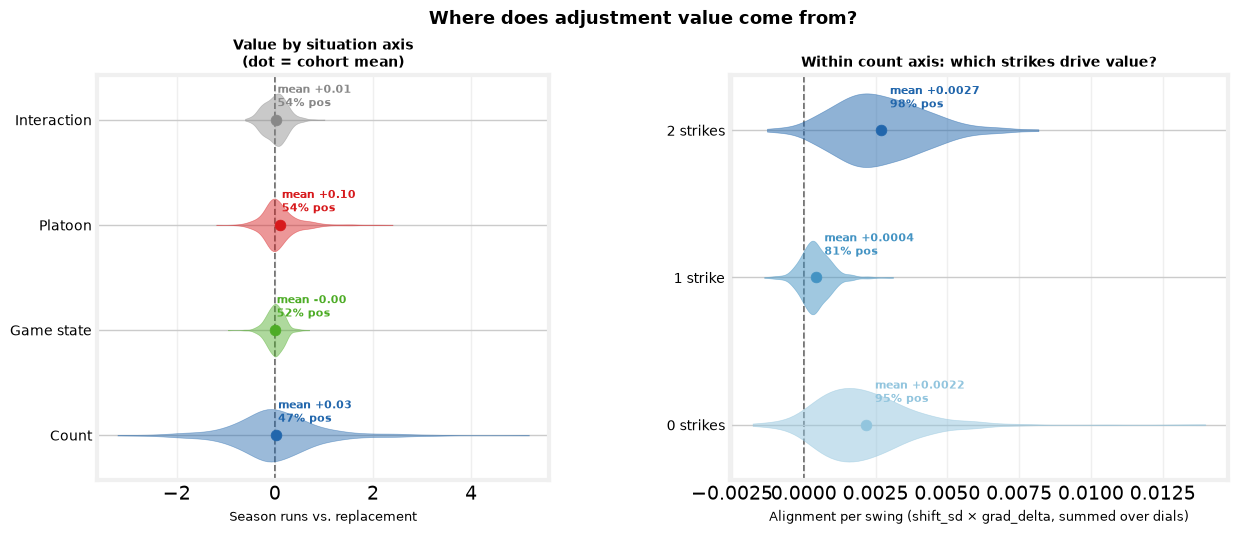

In [18]:
cf = pd.read_parquet(DATA / 'adjustability_value.parquet')
gr = pd.read_parquet(DATA / 'adjustability_gradients.parquet')

AXES = ['runs_count', 'runs_gamestate', 'runs_platoon', 'runs_interaction']
AXIS_LABELS = ['Count', 'Game state', 'Platoon', 'Interaction']
AXIS_COLORS = ['#2166ac', '#4dac26', '#d7191c', '#888888']

# within-count strike alignment: shift_sd * grad_delta per dial, summed per hitter × cell
gr_count = gr[gr.axis == 'count'].copy()
gr_count['align_per_swing'] = gr_count['shift_sd'] * gr_count['grad_delta_runs_per_sd']
KEY = ['batter_id', 'batter_stand']
cell_align = (gr_count.groupby(KEY + ['cell'])['align_per_swing']
              .sum().reset_index().rename(columns={'align_per_swing': 'align'}))

CELL_ORDER = ['0 strikes', '1 strike', '2 strikes']
CELL_COLORS = ['#92c5de', '#4393c3', '#2166ac']

with plt.style.context(FT):
    fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(13, 5),
                                      gridspec_kw={'width_ratios': [1, 1.1], 'wspace': 0.38})
    fig.patch.set_facecolor('white')

    data_by_ax = [cf[c].dropna().values for c in AXES]
    parts = ax_l.violinplot(data_by_ax, positions=range(4), orientation='horizontal',
                            showmedians=False, showextrema=False)
    for pc, col in zip(parts['bodies'], AXIS_COLORS):
        pc.set_facecolor(col); pc.set_alpha(0.45); pc.set_edgecolor(col)
    for i, (col, d, label) in enumerate(zip(AXIS_COLORS, data_by_ax, AXIS_LABELS)):
        mn = np.mean(d)
        pct_pos = 100 * np.mean(d > 0)
        ax_l.scatter(mn, i, color=col, zorder=5, s=60)
        ax_l.text(mn + 0.04, i + 0.22, f'mean {mn:+.2f}\n{pct_pos:.0f}% pos',
                  fontsize=8, va='center', color=col, fontweight='bold')
    ax_l.axvline(0, color='#555', lw=1.2, ls='--', zorder=0)
    ax_l.set_yticks(range(4)); ax_l.set_yticklabels(AXIS_LABELS, fontsize=10)
    ax_l.set_xlabel('Season runs vs. replacement', fontsize=9.5)
    ax_l.set_title('Value by situation axis\n(dot = cohort mean)', fontsize=10, fontweight='bold')
    ax_l.grid(True, axis='x', alpha=0.3)

    for i, (cell, col) in enumerate(zip(CELL_ORDER, CELL_COLORS)):
        vals = cell_align[cell_align.cell == cell]['align'].values
        parts2 = ax_r.violinplot([vals], positions=[i], orientation='horizontal',
                                  showmedians=False, showextrema=False)
        for pc in parts2['bodies']:
            pc.set_facecolor(col); pc.set_alpha(0.5); pc.set_edgecolor(col)
        mn = vals.mean()
        pct = 100 * (vals > 0).mean()
        ax_r.scatter(mn, i, color=col, zorder=5, s=60)
        ax_r.text(mn + 0.0003, i + 0.22, f'mean {mn:+.4f}\n{pct:.0f}% pos',
                  fontsize=8, va='center', color=col, fontweight='bold')
    ax_r.axvline(0, color='#555', lw=1.2, ls='--', zorder=0)
    ax_r.set_yticks(range(3)); ax_r.set_yticklabels(['0 strikes', '1 strike', '2 strikes'], fontsize=10)
    ax_r.set_xlabel('Alignment per swing (shift_sd × grad_delta, summed over dials)', fontsize=9.5)
    ax_r.set_title('Within count axis: which strikes drive value?', fontsize=10, fontweight='bold')
    ax_r.grid(True, axis='x', alpha=0.3)

    fig.suptitle('Where does adjustment value come from?', fontsize=13, fontweight='bold', y=1.01)
    fig.savefig(plot_path('adjustability_situation_breakdown.png'), dpi=150, bbox_inches='tight')
    plt.show()


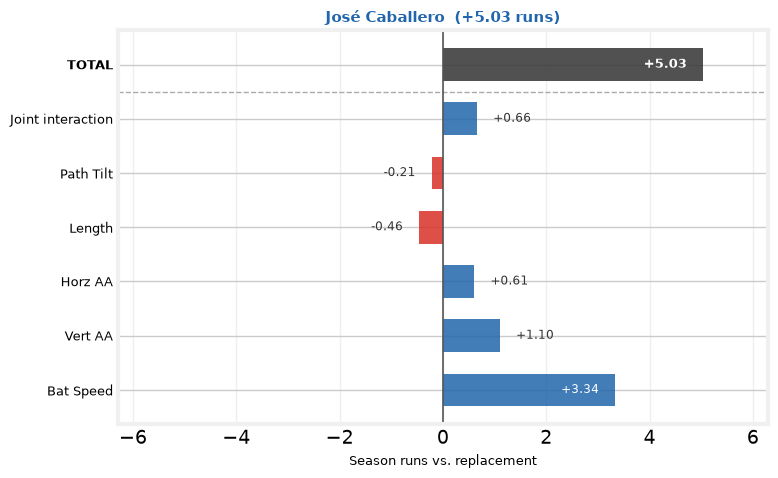

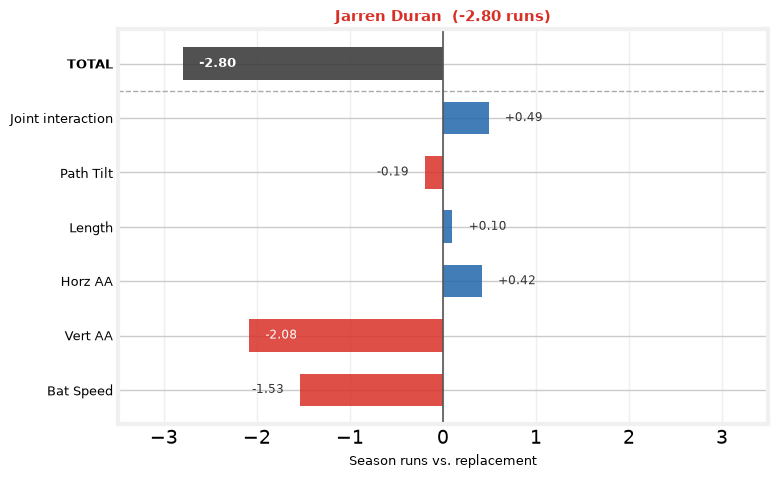

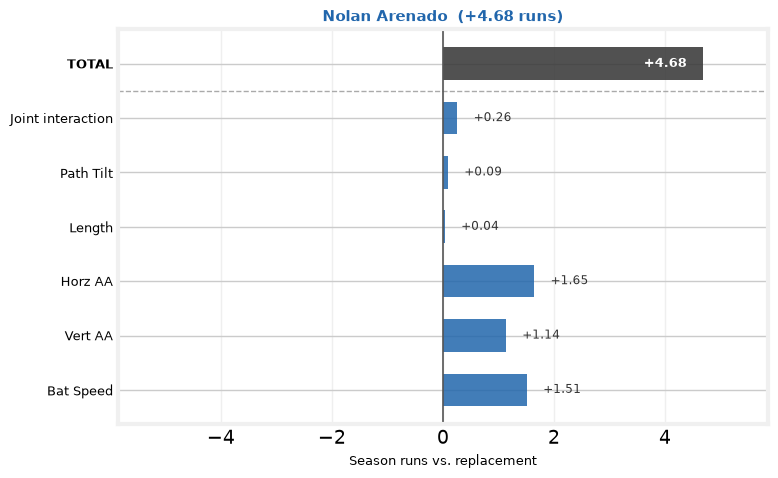

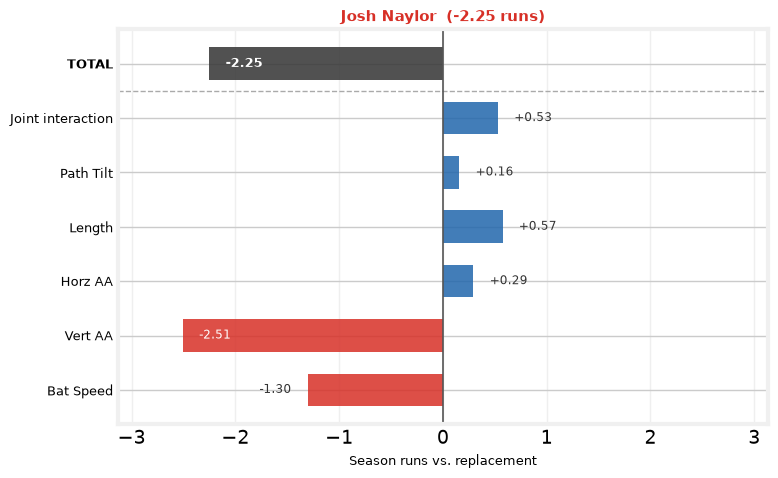

Dial correlations with runs_total:
  bat_speed                      r = +0.775
  vert_attack_angle              r = +0.702
  horz_attack_angle_pull         r = +0.199
  swing_length                   r = -0.401
  swing_path_tilt                r = -0.022
  interaction                    r = +0.012


In [19]:
abl = pd.read_parquet(DATA / 'adjustability_dial_ablation.parquet')

DIAL_ORDER = ['runs_dial_bat_speed', 'runs_dial_vert_attack_angle',
              'runs_dial_horz_attack_angle_pull', 'runs_dial_swing_length',
              'runs_dial_swing_path_tilt', 'runs_dial_interaction']
BAR_LABELS = ['Bat Speed', 'Vert AA', 'Horz AA', 'Length', 'Path Tilt', 'Joint interaction']

FOCAL = [
    ('José Caballero', 'R', '#2166ac'),
    ('Jarren Duran',   'L', '#d73027'),
    ('Nolan Arenado',  'R', '#2166ac'),
    ('Josh Naylor',    'L', '#d73027'),
]

def annotate_bar(ax, v, y, is_total=False):
    fw = 'bold' if is_total else 'normal'
    fs = 9 if is_total else 8.5
    xlim = ax.get_xlim()
    span = xlim[1] - xlim[0]
    # Use a generous threshold so short bars always get outside annotations
    threshold = span * 0.22
    gap = span * 0.025
    if v >= 0:
        if v < threshold:
            ax.text(v + gap, y, f'{v:+.2f}', va='center', ha='left',
                    fontsize=fs, fontweight=fw, color='#333')
        else:
            ax.text(v - gap, y, f'{v:+.2f}', va='center', ha='right',
                    fontsize=fs, fontweight=fw, color='white')
    else:
        if abs(v) < threshold:
            ax.text(v - gap, y, f'{v:+.2f}', va='center', ha='right',
                    fontsize=fs, fontweight=fw, color='#333')
        else:
            ax.text(v + gap, y, f'{v:+.2f}', va='center', ha='left',
                    fontsize=fs, fontweight=fw, color='white')

for name, hand, title_col in FOCAL:
    row = abl[(abl.label == name) & (abl.batter_stand == hand)].iloc[0]
    vals = [row[c] for c in DIAL_ORDER]
    runs_total = row['runs_total']

    all_vals = vals + [runs_total]
    all_labels = BAR_LABELS + ['TOTAL']
    all_colors = ['#2166ac' if v >= 0 else '#d73027' for v in vals] + ['#333333']

    with plt.style.context(FT):
        fig, ax = plt.subplots(figsize=(8, 5))

        y = np.arange(len(all_vals))
        ax.barh(y, all_vals, color=all_colors, height=0.6, alpha=0.85)
        ax.axhline(len(DIAL_ORDER) - 0.5, color='#aaa', lw=1, ls='--')
        ax.axvline(0, color='#555', lw=1.2)

        # Set xlim with padding so outside annotations don't get clipped
        xmax = max(abs(v) for v in all_vals) * 1.25
        ax.set_xlim(-xmax, xmax)

        for i, v in enumerate(all_vals):
            annotate_bar(ax, v, i, is_total=(i == len(DIAL_ORDER)))

        ax.set_yticks(y)
        ax.set_yticklabels(all_labels, fontsize=9)
        for lbl in ax.get_yticklabels():
            if lbl.get_text() == 'TOTAL':
                lbl.set_fontweight('bold')
        ax.set_xlabel('Season runs vs. replacement', fontsize=9)
        ax.set_title(f'{name}  ({runs_total:+.2f} runs)', fontsize=10.5,
                     fontweight='bold', pad=6, color=title_col)
        ax.grid(True, axis='x', alpha=0.3)

        slug = name.split()[-1].lower()
        fig.tight_layout()
        fig.savefig(plot_path(f'adjustability_dial_waterfall_{slug}.png'), dpi=150, bbox_inches='tight')
        plt.show()

# Cohort-level dial correlations with runs_total
print('Dial correlations with runs_total:')
for col in DIAL_ORDER:
    r = abl[col].corr(abl['runs_total'])
    label = col.replace('runs_dial_', '')
    print(f'  {label:<30} r = {r:+.3f}')
